# 04 - Modelado: es_incapacitante (Hito 2)

Compara 5 algoritmos de clasificación para predecir `es_incapacitante`
sobre la población aprobada en `reports/estrategia_data_preparation.md`
(histórico 2019-2022, 564 filas). El notebook solo importa y muestra: la
lógica de preparación vive en `src/prepare.py` y la de modelado en
`src/model.py`.

Objetivo del README (sección 2): recall de al menos 0.70 sobre la clase
no incapacitante (minoritaria), superando el baseline de predecir siempre
la clase mayoritaria (ese baseline tiene recall 0 en la minoritaria).

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd

sys.path.append(str(Path.cwd().parent))

from src.config import FIGURES_DIR, PROCESSED_DIR
from src.model import (
    afinar_con_grid,
    buscar_hiperparametros,
    comparar_modelos,
    construir_cv,
    evaluar_en_test,
    evaluar_multisemilla,
    graficar_comparacion_cv,
    graficar_curvas_roc,
    graficar_matrices_confusion_comparadas,
    modelos_y_distribuciones,
)
from src.prepare import (
    armar_grupo_evento,
    armar_X_y,
    cargar_poblacion_2024_experimental,
    cargar_poblacion_modelado,
    combinar_con_2024,
)

warnings.filterwarnings("ignore", category=FutureWarning)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

df_historico = pd.read_csv(
    PROCESSED_DIR / "accidentes_historico_2012_2022.csv", parse_dates=["fecha_evento"]
)
for columna in ["turno", "programa", "lugar", "puesto_trabajo", "fuente_peligro",
                "actividad_realizada", "mes", "gravedad"]:
    df_historico[columna] = df_historico[columna].astype("category")

poblacion = cargar_poblacion_modelado(df_historico)
X, y = armar_X_y(poblacion)
grupos = armar_grupo_evento(poblacion)

print("Población de modelado:", poblacion.shape)
print("Distribución de y:", y.value_counts().to_dict())
print("X:", X.shape, "| columnas:", list(X.columns))

Población de modelado: (564, 29)
Distribución de y: {True: 409, False: 155}
X: (564, 8) | columnas: ['edad_anios', 'turno', 'programa', 'lugar', 'puesto_trabajo', 'fuente_peligro', 'actividad_realizada', 'mes']


## Partición train/test

80/20, estratificada por `es_incapacitante` y agrupada por evento (filas
del mismo accidente con varios trabajadores afectados van al mismo lado).
Se usa el primer pliegue de un `StratifiedGroupKFold` de 5, tal como se
acordó en la estrategia de preparación de datos.

In [2]:
cv_particion = construir_cv()
indice_train, indice_test = next(cv_particion.split(X, y, groups=grupos))

X_train, X_test = X.iloc[indice_train], X.iloc[indice_test]
y_train, y_test = y.iloc[indice_train], y.iloc[indice_test]
grupos_train = grupos.iloc[indice_train]

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test: ", X_test.shape, y_test.value_counts().to_dict())
print(
    "Grupos compartidos entre train y test:",
    len(set(grupos.iloc[indice_train]) & set(grupos.iloc[indice_test])),
)

Train: (451, 8) {True: 327, False: 124}
Test:  (113, 8) {True: 82, False: 31}
Grupos compartidos entre train y test: 0


## Comparación de 5 algoritmos (experimentación: búsqueda aleatoria)

Regresión Logística, KNN, SVM (RBF), Random Forest y Gradient Boosting
(`HistGradientBoostingClassifier`), cada uno con `RandomizedSearchCV`
(40 combinaciones, validación cruzada de 5 pliegues agrupada por evento,
solo sobre train). Se reportan 3 métricas; el modelo gana por recall de
la clase minoritaria, que es el objetivo fijado en el README.

In [3]:
tabla_comparacion, busquedas = comparar_modelos(X_train, y_train, grupos_train, n_iter=40)
tabla_comparacion.drop(columns="mejores_parametros")

,modelo,recall_minoritaria,f1_minoritaria,roc_auc
0,svm_rbf,0.880000,0.503260,0.806181
1,random_forest,0.782667,0.693248,0.880876
2,gradient_boosting,0.766000,0.683388,0.877754
3,regresion_logistica,0.702000,0.617898,0.847726
4,knn,0.516000,0.577251,0.791149


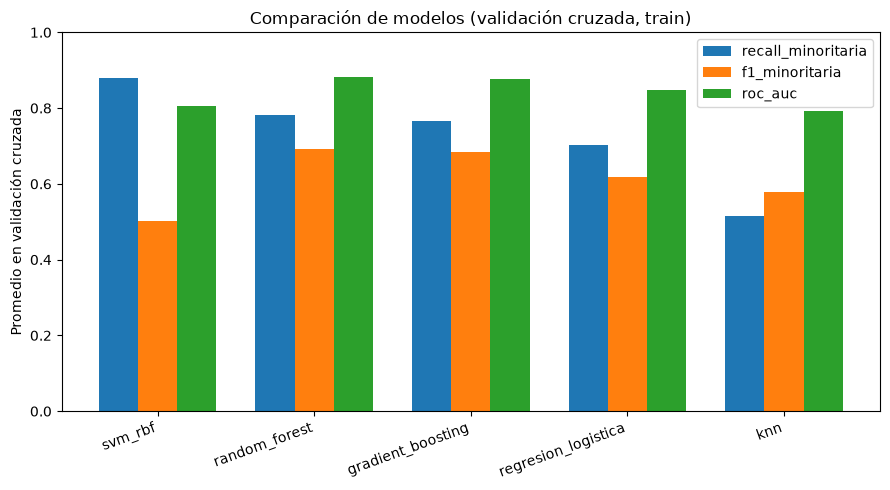

In [4]:
fig = graficar_comparacion_cv(tabla_comparacion)
fig.savefig(FIGURES_DIR / "modelado_comparacion_cv.png", dpi=100)

### Hallazgo

4 de los 5 algoritmos superan el recall de 0.70 que fija el README en
validación cruzada sobre train: SVM (0.880), Random Forest (0.783),
Gradient Boosting (0.766) y Regresión Logística (0.702, al límite). KNN
queda claramente abajo (0.516); no tiene `class_weight`, así que el
desbalance lo afecta más que a los demás.

El orden cambia si se mira F1 en vez de recall: SVM lidera en recall pero
su F1 (0.503) es el más bajo de los cuatro que cumplen el umbral, señal de
que gana recall a costa de muchos falsos positivos (predecir
incapacitante cuando no lo es). Random Forest y Gradient Boosting
mantienen un F1 bastante mejor (0.693 y 0.683) con un recall apenas menor.
Por eso se afinan los dos finalistas: el de mayor recall (SVM) y el de
mayor F1 si es distinto (Random Forest), en vez de quedarse solo con el
primer lugar de la tabla.

## Experimentación: afinamiento con GridSearchCV

Se afinan con `GridSearchCV` (grilla exhaustiva acotada alrededor de los
mejores hiperparámetros) los dos modelos más relevantes de la comparación:
el de mayor recall minoritario y, si es distinto, el de mejor F1
minoritario (para no perder de vista el balance precisión/recall).

In [5]:
ganador_recall = tabla_comparacion.iloc[0]
ganador_f1 = tabla_comparacion.sort_values("f1_minoritaria", ascending=False).iloc[0]

finalistas = {ganador_recall["modelo"]}
if ganador_f1["modelo"] != ganador_recall["modelo"]:
    finalistas.add(ganador_f1["modelo"])

print("Finalistas a afinar:", finalistas)

grillas_finas = {}
for nombre in finalistas:
    busqueda = busquedas[nombre]
    modelo_base = busqueda.best_estimator_.named_steps["modelo"]
    grillas_finas[nombre] = afinar_con_grid(
        nombre, modelo_base, busqueda.best_params_, X_train, y_train, grupos_train
    )
    print(f"\n{nombre}: mejores params afinados = {grillas_finas[nombre].best_params_}")

Finalistas a afinar: {'random_forest', 'svm_rbf'}



random_forest: mejores params afinados = {'modelo__max_depth': 12, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 7, 'modelo__n_estimators': 1000}



svm_rbf: mejores params afinados = {'modelo__C': np.float64(0.5125306745160588), 'modelo__gamma': np.float64(0.002519959333787251)}


## Evaluación final en test

Cada finalista, ya afinado, se evalúa una sola vez sobre el test
(113 filas, 31 no incapacitantes).

In [6]:
resultados_test = {}
for nombre, grilla in grillas_finas.items():
    resultados_test[nombre] = evaluar_en_test(grilla.best_estimator_, X_test, y_test)

tabla_test = pd.DataFrame(resultados_test).T.drop(columns="matriz_confusion")
tabla_test

,recall_minoritaria,recall_minoritaria_ic95,precision_minoritaria,recall_mayoritaria,precision_mayoritaria,f1_minoritaria,roc_auc
random_forest,0.806452,"(0.6371974218820453, 0.9081299163841389)",0.694444,0.865854,0.922078,0.746269,0.888867
svm_rbf,0.258065,"(0.13701705906393746, 0.432461358094338)",1.0,1.0,0.780952,0.410256,0.79229


In [7]:
for nombre, resultado in resultados_test.items():
    ic = resultado["recall_minoritaria_ic95"]
    print(f"{nombre}: recall minoritaria = {resultado['recall_minoritaria']:.3f} "
          f"(IC 95%: {ic[0]:.3f} - {ic[1]:.3f})")

random_forest: recall minoritaria = 0.806 (IC 95%: 0.637 - 0.908)
svm_rbf: recall minoritaria = 0.258 (IC 95%: 0.137 - 0.432)


**Matrices de confusión en test**, una sola imagen para comparar los dos
finalistas de un vistazo: en cada celda, el conteo de filas y, debajo, el
% de esa fila (que es justo el recall de esa clase real).

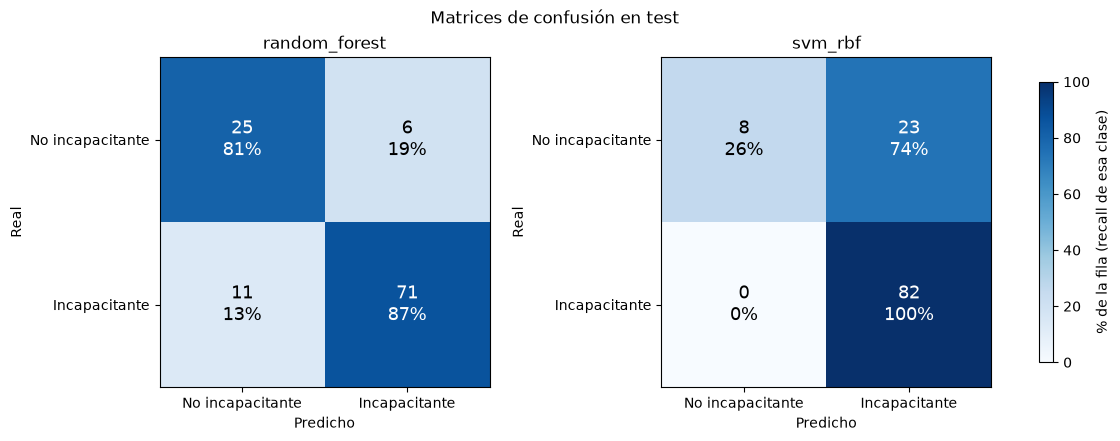

In [8]:
fig = graficar_matrices_confusion_comparadas(resultados_test)
fig.savefig(FIGURES_DIR / "modelado_matrices_confusion.png", dpi=100, bbox_inches="tight")

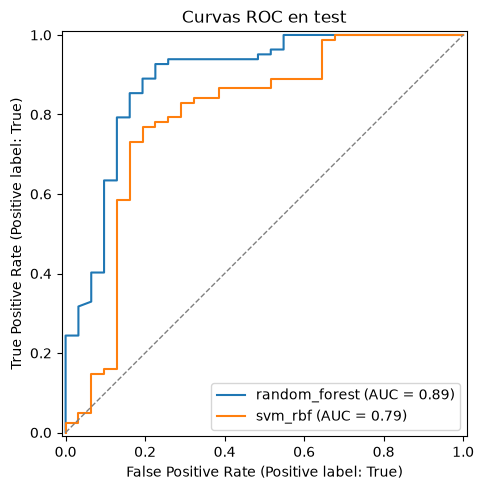

In [9]:
modelos_finales = {nombre: grilla.best_estimator_ for nombre, grilla in grillas_finas.items()}
fig = graficar_curvas_roc(modelos_finales, X_test, y_test)
fig.savefig(FIGURES_DIR / "modelado_curvas_roc.png", dpi=100)

### Hallazgo final y recomendación

**El resultado más importante de este notebook no es qué modelo ganó, es
que confiar solo en el score de validación cruzada hubiera sido un
error.** SVM, el que lideraba la comparación (recall 0.880 en CV), se
desploma a 0.258 en el test: de 31 casos no incapacitantes, solo acierta
8, porque clasifica casi todo como incapacitante (acierta las 82 filas de
esa clase, recall 1.0, pero sin distinguir nada). Es un caso de
sobreajuste a los pliegues de validación cruzada, agravado porque el
desbalance deja muy pocos casos de la clase minoritaria en cada pliegue.

Random Forest, en cambio, se mantiene estable: 0.783 en validación
cruzada y 0.806 en test (de 31 no incapacitantes, acierta 25; de 93
incapacitantes, acierta 71), con un intervalo de confianza del 95% de
0.637 a 0.908. Precisión de la clase minoritaria 0.694, F1 0.746 y
AUC-ROC 0.889.

**Recomendación: Random Forest** (`max_depth=12`, `max_features=sqrt`,
`min_samples_leaf=7`, `n_estimators=1000`). Cumple el objetivo de recall
del README con un balance razonable de precisión, y su desempeño en CV y
en test es consistente, a diferencia de SVM. No se recomienda SVM pese a
su score más alto en la comparación inicial.

## Validación con varias semillas

Una sola partición train/test puede ser optimista o pesimista por azar
con tan pocos datos. Se reajusta Random Forest (mismos hiperparámetros ya
elegidos, sin volver a buscarlos) sobre 10 particiones distintas, para
reportar un rango de recall en vez de un solo número.

In [10]:
mejor_rf = grillas_finas["random_forest"].best_estimator_
tabla_semillas = evaluar_multisemilla(mejor_rf, X, y, grupos, semillas=range(10))
tabla_semillas

,semilla,recall_minoritaria,precision_minoritaria,f1_minoritaria,roc_auc
0,0,0.870968,0.642857,0.739726,0.922895
1,1,0.967742,0.625000,0.759494,0.922109
2,2,0.774194,0.585366,0.666667,0.879229
3,3,0.838710,0.634146,0.722222,0.895358
4,4,0.838710,0.530612,0.650000,0.884343
5,5,0.838710,0.684211,0.753623,0.902636
6,6,0.709677,0.647059,0.676923,0.845004
7,7,0.741935,0.575000,0.647887,0.848938
8,8,0.709677,0.594595,0.647059,0.870574
9,9,0.838710,0.684211,0.753623,0.904996


In [11]:
resumen_semillas = tabla_semillas.drop(columns="semilla").describe()
resumen_semillas.loc[["mean", "std", "min", "max"]]

,recall_minoritaria,precision_minoritaria,f1_minoritaria,roc_auc
mean,0.812903,0.620306,0.701722,0.887608
std,0.080178,0.048973,0.048299,0.027295
min,0.709677,0.530612,0.647059,0.845004
max,0.967742,0.684211,0.759494,0.922895


### Hallazgo

El recall minoritario de Random Forest varía entre 0.710 y 0.968 según la
semilla, con media 0.813 y desviación estándar 0.080. **Las 10 particiones
superan el 0.70 que fija el README**, incluida la peor (semilla 6, 0.710):
el modelo recomendado no depende de haber tenido suerte con la partición
del notebook. El número de la sección anterior (0.806 en una sola
partición) queda, en este contexto, cerca de la media del rango, ni
optimista ni pesimista.

## Experimento adicional: ¿ayuda el sobremuestreo sintético (SMOTENC)?

Se evaluó agregar `SMOTENC` (sobremuestreo sintético que respeta columnas
categóricas) como sugerencia opcional para compensar el tamaño chico de
la clase minoritaria (155 filas de 564). **No es lo mismo que generar un
dataset simulado completo**, que ya se descartó en
`reports/estrategia_data_preparation.md` (sección "Aumento de datos"): un
accidente inventado no es evidencia de SST. SMOTENC es distinto — genera
vecinos interpolados entre casos reales, y corre **solo dentro de cada
fold de train** (vía `imblearn.pipeline.Pipeline`, nunca toca test), tal
como esa misma sección ya dejaba previsto si se probara.

Se compara el mismo Random Forest recomendado (mismos hiperparámetros),
con y sin SMOTENC, en 5 intensidades de balanceo (de 1:1 hasta un
`sampling_strategy=0.4`, el más leve), sobre las mismas 10 particiones de
`evaluar_multisemilla()`.

In [12]:
from src.model import comparar_smote, graficar_comparacion_smote

resultados_smote = comparar_smote(
    mejor_rf, X, y, grupos, mejor_rf.named_steps["modelo"]
)
for etiqueta, tabla in resultados_smote.items():
    print(f"{etiqueta}: recall medio = {tabla['recall_minoritaria'].mean():.3f}, "
          f"min = {tabla['recall_minoritaria'].min():.3f}")

Random Forest (recomendado, sin SMOTENC): recall medio = 0.813, min = 0.710
SMOTENC 1:1: recall medio = 0.690, min = 0.581
SMOTENC (sampling_strategy=0.75): recall medio = 0.713, min = 0.613
SMOTENC (sampling_strategy=0.6): recall medio = 0.745, min = 0.645
SMOTENC (sampling_strategy=0.5): recall medio = 0.768, min = 0.677
SMOTENC (sampling_strategy=0.4): recall medio = 0.806, min = 0.677


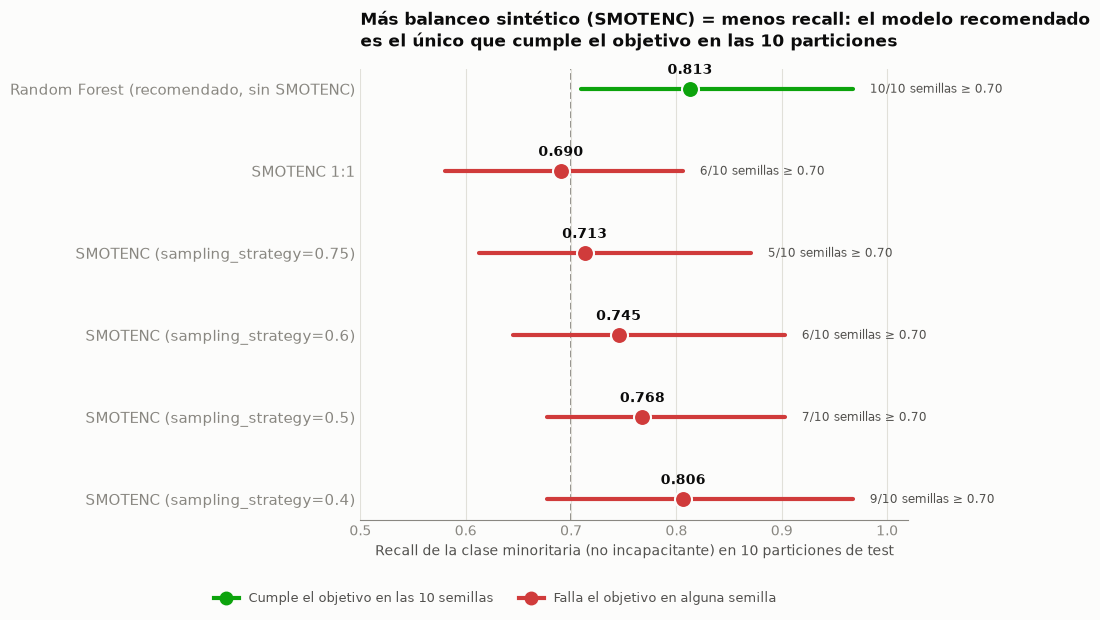

In [13]:
fig = graficar_comparacion_smote(resultados_smote)
fig.savefig(FIGURES_DIR / "modelado_comparacion_smote.png", dpi=150, bbox_inches="tight")

### Hallazgo

**SMOTENC no mejora el modelo para el objetivo del README — lo empeora, y
cuanto más balanceo sintético se agrega, peor.** El modelo recomendado
(sin SMOTENC) es el único que supera 0.70 de recall en las 10 semillas
(media 0.813, mínimo 0.710). Con SMOTENC 1:1 el recall medio cae a 0.690
(solo 6 de 10 semillas pasan el umbral); con la intensidad más leve
(`sampling_strategy=0.4`) se acerca al baseline (media 0.806) pero sigue
sin igualarlo (9 de 10 semillas, no 10 de 10).

La explicación es consistente con la mecánica de cada técnica: el
objetivo del README prioriza recall sobre precisión, y
`class_weight="balanced"` ya penaliza directamente los falsos negativos
de la clase minoritaria. SMOTENC, en cambio, suaviza la frontera de
decisión interpolando vecinos — mejora precisión y F1, pero a costa de
recall, en las 4 intensidades probadas sin excepción.

**No se adopta SMOTENC.** Se documenta como alternativa evaluada y
descartada con evidencia cuantitativa (ver
`reports/estrategia_data_preparation.md`), no como una idea sin probar.
El modelo oficial del Hito 2 sigue siendo Random Forest con
`class_weight="balanced"`, sin sobremuestreo.

## Experimento adicional: sumar el año 2024 (no es el resultado oficial)

**Esta sección es exploratoria, no reemplaza el modelo recomendado de
arriba.** `accidentes_2024.csv` no trae la columna `gravedad`, así que no
se puede derivar `es_incapacitante` de la forma ya validada. Se usa como
proxy `dias_dm > 0`: esa equivalencia coincide con la etiqueta real en 458
de 459 filas del histórico 2019-2022, pero **no está confirmada por el
equipo de SST específicamente para la fuente 2024** (ver
`src.prepare.cargar_poblacion_2024_experimental`, y la pregunta pendiente
en `reports/estrategia_data_preparation.md`). Se documenta el supuesto de
forma explícita, no se oculta.

In [14]:
df_2024 = pd.read_csv(PROCESSED_DIR / "accidentes_2024.csv", parse_dates=["fecha_evento"])
poblacion_2024 = cargar_poblacion_2024_experimental(df_2024)
poblacion_combinada = combinar_con_2024(poblacion, poblacion_2024)

X_comb, y_comb = armar_X_y(poblacion_combinada)
grupos_comb = armar_grupo_evento(poblacion_combinada)

print("Población combinada (2019-2022 + 2024 experimental):", poblacion_combinada.shape)
print("Distribución de y:", y_comb.value_counts().to_dict())

Población combinada (2019-2022 + 2024 experimental): (828, 11)
Distribución de y: {True: 491, False: 337}


In [15]:
indice_train_comb, indice_test_comb = next(cv_particion.split(X_comb, y_comb, groups=grupos_comb))
X_train_comb = X_comb.iloc[indice_train_comb]
X_test_comb = X_comb.iloc[indice_test_comb]
y_train_comb = y_comb.iloc[indice_train_comb]
y_test_comb = y_comb.iloc[indice_test_comb]
grupos_train_comb = grupos_comb.iloc[indice_train_comb]

print("Train:", X_train_comb.shape, y_train_comb.value_counts().to_dict())
print("Test: ", X_test_comb.shape, y_test_comb.value_counts().to_dict())

Train: (662, 8) {True: 393, False: 269}
Test:  (166, 8) {True: 98, False: 68}


In [16]:
modelo_rf_base, distribuciones_rf = modelos_y_distribuciones()["random_forest"]
busqueda_comb = buscar_hiperparametros(
    "random_forest", modelo_rf_base, distribuciones_rf,
    X_train_comb, y_train_comb, grupos_train_comb, n_iter=40,
)
grilla_comb = afinar_con_grid(
    "random_forest",
    busqueda_comb.best_estimator_.named_steps["modelo"],
    busqueda_comb.best_params_,
    X_train_comb, y_train_comb, grupos_train_comb,
)
print("Mejores params (combinado):", grilla_comb.best_params_)

Mejores params (combinado): {'modelo__max_depth': 16, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 358}


In [17]:
resultado_comb = evaluar_en_test(grilla_comb.best_estimator_, X_test_comb, y_test_comb)
ic = resultado_comb["recall_minoritaria_ic95"]
print(f"Recall minoritaria en test (combinado): {resultado_comb['recall_minoritaria']:.3f} "
      f"(IC 95%: {ic[0]:.3f} - {ic[1]:.3f})")
print("Precisión minoritaria:", round(resultado_comb["precision_minoritaria"], 3))
print("F1 minoritaria:", round(resultado_comb["f1_minoritaria"], 3))
print("AUC-ROC:", round(resultado_comb["roc_auc"], 3))
print("Matriz de confusión:")
print(resultado_comb["matriz_confusion"])

Recall minoritaria en test (combinado): 0.868 (IC 95%: 0.767 - 0.929)
Precisión minoritaria: 0.711
F1 minoritaria: 0.781
AUC-ROC: 0.872
Matriz de confusión:
[[59  9]
 [24 74]]


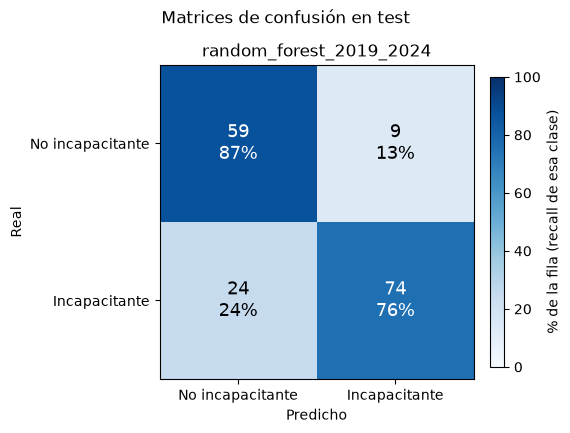

In [18]:
fig = graficar_matrices_confusion_comparadas({"random_forest_2019_2024": resultado_comb})
fig.savefig(FIGURES_DIR / "modelado_matriz_confusion_2024.png", dpi=100, bbox_inches="tight")

In [19]:
tabla_semillas_comb = evaluar_multisemilla(
    grilla_comb.best_estimator_, X_comb, y_comb, grupos_comb, semillas=range(10)
)
resumen_semillas_comb = tabla_semillas_comb.drop(columns="semilla").describe()
resumen_semillas_comb.loc[["mean", "std", "min", "max"]]

,recall_minoritaria,precision_minoritaria,f1_minoritaria,roc_auc
mean,0.851844,0.701530,0.768402,0.890109
std,0.025252,0.045787,0.026817,0.020141
min,0.805970,0.637363,0.729560,0.849389
max,0.882353,0.788732,0.819444,0.914391


### Hallazgo del experimento

Sumar 2024 cambia el panorama favorablemente, si se acepta el supuesto
del proxy: la población pasa de 564 a 828 filas, y el desbalance mejora
de 72.5/27.5 a 59.3/40.7 (2024 aporta 182 casos `dias_dm == 0` frente a
82 `dias_dm > 0`, al revés de la proporción del histórico). El test crece
de 31 a 68 casos no incapacitantes, lo que angosta bastante el intervalo
de confianza del recall.

Con Random Forest reafinado sobre esta población combinada: recall
minoritario 0.868 en test (IC 95%: 0.767 a 0.929), precisión 0.711, F1
0.781, AUC-ROC 0.872 (de 68 no incapacitantes, acierta 59; de 98
incapacitantes, acierta 74). En 10 semillas, el recall va de 0.806 a
0.882 (media 0.852, desviación 0.025): más alto y bastante más estable
que el modelo oficial con 2019-2022 solo.

**Esto no cambia la recomendación del Hito 2.** El resultado es mejor,
pero depende de que `dias_dm > 0` realmente equivalga a incapacitante en
`accidentes_2024.csv`, algo que todavía no confirmó el equipo de SST para
esta fuente específica. Si se confirma, este experimento es el candidato
natural para la siguiente iteración del modelo.

## Limitaciones y próximos pasos

- **Experimento de 2024 pendiente de validación**: la etiqueta usada para
  esa fuente (`dias_dm > 0`) es un supuesto, no un hecho confirmado por
  SST (ver sección del experimento arriba). El modelo oficial de este
  hito sigue siendo el de 2019-2022, con `es_incapacitante` derivada de
  `gravedad`.
- **`experiencia_puesto_meses`, `sexo`, `area_responsabilidad` y `anio`
  quedan fuera de X** (ver estrategia de preparación de datos) porque su
  disponibilidad depende de la clase objetivo en 2019-2022. Vale la pena
  revisar si esa limitación se mantiene una vez validado el experimento
  de 2024.
- **Texto libre no usado**: `descripcion_accidente` no entra al modelo
  (fuera de alcance de esta fase, ver README sección 5). Podría aportar
  señal adicional en una fase futura con procesamiento de texto.
- **`turno` de 2024 no se unificó con el del histórico** (códigos de una
  letra como `D`/`M`/`N`/`T`/`C` frente a `DIA`/`TARDE`/`NOCHE`/
  `TURNO_1/2/3`): no hay forma de confirmar sin adivinar qué significa
  cada letra, así que quedan como categorías separadas (ver
  `src.prepare.cargar_poblacion_2024_experimental`).